[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LucaswasTaken/Openhardware-hpc/blob/master/exercicios/modelo_relatorio.ipynb)

# Relatório de HPC — modelo

**Nome:** …  **Exercício:** …  **Caminho:** CPU (Numba) / GPU (CuPy)

> 🎬 **Vídeo (1 min):** [Como fazer o relatório](https://lucaswastaken.github.io/Openhardware-hpc/#v11)

**Como usar este modelo** — ele já vem resolvido com o exemplo da lista (energia de deformação de molas). Para o seu exercício:
1. Rode tudo uma vez (*Ambiente de execução → Executar tudo*) para ver como fica.
2. Troque **só as células marcadas com ✏️**: a função serial (seção 2) e a versão acelerada (seção 3 ou 5).
3. Rode tudo de novo. Medidas, conferência, tabela e gráficos saem sozinhos.
4. Escreva o texto nas seções 1 e 6.

Primeira vez? Veja [INSTALACAO.md](https://github.com/LucaswasTaken/Openhardware-hpc/blob/master/exercicios/INSTALACAO.md). Caminho GPU no Colab: *Ambiente de execução → Alterar o tipo → T4 GPU*.

### Ferramentas (não precisa mexer)
`medir(f, ...)` roda a função uma vez para **aquecer** (o Numba compila, a GPU inicializa), depois mede 5 vezes e devolve o **menor** tempo — que é o mais confiável. Na GPU ele **sincroniza** antes de parar o relógio.

In [1]:
import os, sys, time, platform
import numpy as np
import matplotlib.pyplot as plt

try:
    import cupy as cp
    GPU = cp.cuda.runtime.getDeviceCount() > 0
except Exception:
    cp, GPU = None, False

def sincroniza():
    if GPU: cp.cuda.Device().synchronize()

def medir(f, *args, repeticoes=5):
    """Aquece uma vez, mede `repeticoes` vezes e devolve (menor tempo em s, resultado)."""
    r = f(*args); sincroniza()
    tempos = []
    for _ in range(repeticoes):
        sincroniza(); t = time.perf_counter(); r = f(*args); sincroniza()
        tempos.append(time.perf_counter() - t)
    return min(tempos), r

nome_gpu = cp.cuda.runtime.getDeviceProperties(0)["name"] if GPU else b"-"
print(f"Python {platform.python_version()} · {os.cpu_count()} núcleos lógicos · "
      f"GPU: {nome_gpu.decode() if isinstance(nome_gpu, bytes) else nome_gpu} · Colab: {'google.colab' in sys.modules}")

C:\Users\lucas\Documents\GitHub\Openhardware-hpc\.venv\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Python 3.12.13 · 12 núcleos lógicos · GPU: NVIDIA GeForce MX570 A · Colab: False


## 1. Problema
*(2–3 linhas: o que é calculado, aplicação em engenharia, tamanho do problema)*

Exemplo: energia de deformação $U = \tfrac12\sum k_i\delta_i^2$ de 20 milhões de molas.

## 2. ✏️ Função serial (a referência) e os dados
Cole aqui a função serial do seu exercício (está pronta na lista) e crie os dados. O Python puro é lento: medimos num pedaço menor e multiplicamos.

In [2]:
def serial(k, d):                        # ✏️ troque pela função serial do seu exercício
    u = 0.0
    for i in range(len(k)):
        u += 0.5 * k[i] * d[i] * d[i]
    return u

N = 20_000_000                           # ✏️ tamanho do problema (fixo em todas as medidas)
rng = np.random.default_rng(0)
k = rng.uniform(1e6, 1e8, N)             # ✏️ seus dados
d = rng.normal(0, 1e-3, N)
dados = (k, d)                           # ✏️ argumentos que todas as versões recebem

ref = 0.5 * np.dot(k, d * d)             # ✏️ resultado de referência (NumPy, ou a própria serial se for rápida)

pedaco = 1_000_000                       # Python puro: mede 1 milhão e extrapola
t_python = medir(serial, k[:pedaco], d[:pedaco], repeticoes=1)[0] * N / pedaco
t_numpy = medir(lambda k, d: 0.5 * np.dot(k, d * d), *dados)[0]   # ✏️ versão NumPy, se houver
print(f"Python puro (estimado): {t_python:.2f} s   NumPy: {t_numpy:.4f} s   referência = {ref:.6e}")

Python puro (estimado): 7.82 s   NumPy: 0.0968 s   referência = 5.049525e+08


## 3. ✏️ Caminho CPU — versão Numba
Três mudanças em relação à serial: `@njit(parallel=True)`, `range` → `prange`, e conferir com a referência. *(Caminho GPU? Pule para a seção 5.)*

In [3]:
from numba import njit, prange, set_num_threads, get_num_threads

@njit(parallel=True)
def acelerada(k, d):                     # ✏️ sua versão Numba (mesmos argumentos de `dados`)
    u = 0.0
    for i in prange(k.size):
        u += 0.5 * k[i] * d[i] * d[i]
    return u

t, r = medir(acelerada, *dados)
assert np.isclose(r, ref, rtol=1e-9), (r, ref)        # CONFERÊNCIA: rápido e errado vale zero
print(f"Numba ({get_num_threads()} threads): {t:.4f} s → {r:.6e}  ✓ confere com a referência")

Numba (12 threads): 0.0084 s → 5.049525e+08  ✓ confere com a referência


## 4. Escalabilidade forte — o mesmo problema com 1, 2, 4… threads
Não precisa mexer. **Speedup** = tempo com 1 thread ÷ tempo com p threads. **Eficiência** = speedup ÷ p (100% = perfeito).

threads  tempo [s]  speedup eficiência
      1     0.0471    1.00×       100%
      2     0.0274    1.72×        86%
      4     0.0172    2.74×        68%
      6     0.0133    3.53×        59%
      8     0.0106    4.45×        56%
     12     0.0088    5.35×        45%

Python puro → Numba com 12 threads: 889× mais rápido


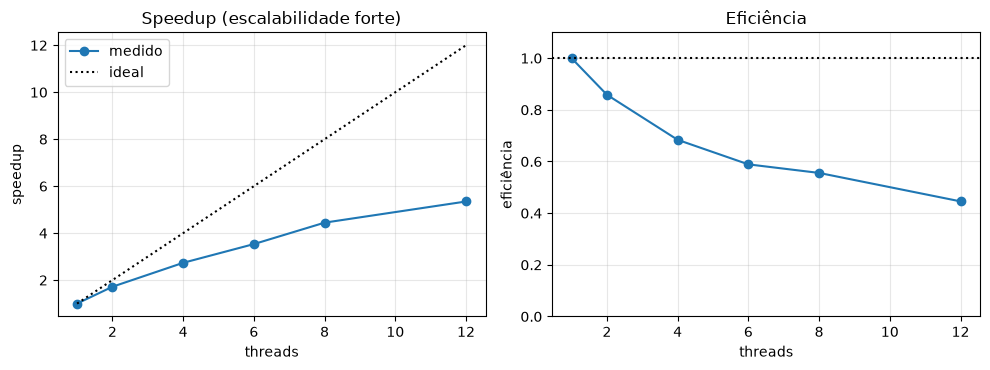

In [4]:
P_MAX = get_num_threads()
ps = sorted({p for p in (1, 2, 4, 6, 8, 12, 16, 24, 32) if p <= P_MAX} | {P_MAX})
T = {}
for p in ps:
    set_num_threads(p)
    T[p], r = medir(acelerada, *dados)
    assert np.isclose(r, ref, rtol=1e-9)
set_num_threads(P_MAX)
S = {p: T[1] / T[p] for p in ps}
E = {p: S[p] / p for p in ps}

print(f"{'threads':>7} {'tempo [s]':>10} {'speedup':>8} {'eficiência':>10}")
for p in ps:
    print(f"{p:>7} {T[p]:>10.4f} {S[p]:>7.2f}× {E[p]:>10.0%}")
print(f"\nPython puro → Numba com {P_MAX} threads: {t_python / T[P_MAX]:,.0f}× mais rápido")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.plot(ps, [S[p] for p in ps], "o-", label="medido"); a1.plot(ps, ps, "k:", label="ideal")
a1.set(xlabel="threads", ylabel="speedup", title="Speedup (escalabilidade forte)"); a1.legend()
a2.plot(ps, [E[p] for p in ps], "o-"); a2.axhline(1, color="k", ls=":")
a2.set(xlabel="threads", ylabel="eficiência", ylim=(0, 1.1), title="Eficiência")
for a in (a1, a2): a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("escalabilidade_forte.png", dpi=150); plt.show()

## 5. ✏️ Caminho GPU — a escada de speedup (CuPy)
Na GPU não se escolhe o número de trabalhadores; comparamos o **mesmo problema** em cada versão. Meça duas vezes: com o dado **já na GPU** e **contando a cópia** RAM → GPU — essa diferença é a principal lição. (Sem GPU, esta seção mostra só os degraus de CPU.)

           Python puro:    7.8243 s          1× o Python
                 NumPy:    0.0968 s         81× o Python
        Numba 1 thread:    0.0471 s        166× o Python
      Numba 12 threads:    0.0088 s        889× o Python
    CuPy (dado na GPU):    0.0695 s        113× o Python
          CuPy + cópia:    0.1541 s         51× o Python


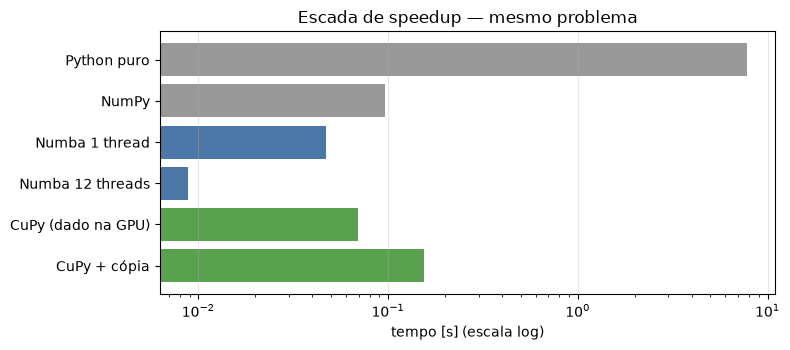

In [5]:
def acelerada_gpu(kg, dg):               # ✏️ sua versão CuPy (recebe arrays já na GPU)
    return 0.5 * cp.dot(kg, dg * dg)

escada = {"Python puro": t_python, "NumPy": t_numpy,
          "Numba 1 thread": T[1], f"Numba {P_MAX} threads": T[P_MAX]}
if GPU:
    dados_gpu = tuple(cp.asarray(a) for a in dados)                     # copia RAM → GPU
    t, r = medir(acelerada_gpu, *dados_gpu)
    assert np.isclose(float(r), ref, rtol=1e-9), (float(r), ref)        # CONFERÊNCIA
    escada["CuPy (dado na GPU)"] = t
    escada["CuPy + cópia"] = medir(lambda *a: float(acelerada_gpu(*(cp.asarray(x) for x in a))), *dados, repeticoes=3)[0]

for nome, t in escada.items():
    print(f"{nome:>22}: {t:9.4f} s   {t_python / t:8,.0f}× o Python")
plt.figure(figsize=(8, 3.6))
plt.barh(list(escada), list(escada.values()), color=["#999"] * 2 + ["#4c78a8"] * 2 + ["#59a14f"] * (len(escada) - 4))
plt.xscale("log"); plt.xlabel("tempo [s] (escala log)"); plt.gca().invert_yaxis(); plt.grid(alpha=.3, axis="x")
plt.title("Escada de speedup — mesmo problema"); plt.tight_layout(); plt.savefig("escada.png", dpi=150); plt.show()

## 6. Análise
Responda com os seus números:
- **O que limitou o ganho?** Algumas causas comuns:
  - *memória*: cada dado tem poucas contas, e as threads esperam a RAM (calcule GB/s = bytes lidos ÷ tempo);
  - *parte que não paraleliza*: juntar resultados, a etapa final;
  - *cópia para a GPU*: compare "dado na GPU" × "+ cópia";
  - *problema pequeno*: o custo de dividir o trabalho é maior que o trabalho.
- **Valeu a pena?** Compare com o Python puro e com o NumPy.
- **IA:** em uma linha, o que a IA fez e o que você precisou corrigir.

## 7. Conclusões e limitações
*(3–4 linhas)*